## Basic Corrective RAG


In [1]:
!pip install python-dotenv langchain langchain-community langchain-ollama langchain-text-splitters langgraph faiss-cpu pypdf pydantic tavily-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from typing import List, TypedDict
import time

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END

/tmp/ipykernel_2818/2296324641.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [12]:
import os
os.environ["OLLAMA_BASE_URL"] = "https://reentry-subject-mannish.ngrok-free.dev"

In [6]:
docs = (
    PyPDFLoader(r"./ML Book.pdf").load()
)

In [7]:
len(docs)

564

In [8]:
# Create Chunks

chunks = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
).split_documents(docs)

In [9]:
#  Clean text to avoid UnicodeEncodeError (surrogates from PDF extraction)

for d in chunks:
  d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [10]:
len(chunks)

1527

In [11]:
# Prepare embedding with local model
embeddings = OllamaEmbeddings(model='nomic-embed-text', base_url="https://reentry-subject-mannish.ngrok-free.dev")

In [13]:
# Setup Vector Store

vector_store = FAISS.from_documents(chunks, embeddings)

In [14]:
vector_store.save_local("vectore_store")

In [15]:
# Retriever

retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [34]:
# LLM
llm = ChatOllama(model="llama3.1:8b", temperature=0, base_url="https://reentry-subject-mannish.ngrok-free.dev")

In [27]:
# Define State

class State(TypedDict):
  question: str
  docs: List[Document]
  answer: str

In [28]:
# function to retrieve using retriever
def retrieve(state):
  q = state['question']
  return {"docs": retriever.invoke(q)}

In [29]:
# prompt

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

In [30]:
def generate(state):
  context = "\n\n".join(d.page_content for d in state['docs'])
  out = (prompt | llm).invoke({"question": state['question'], "context": context})
  return {"answer": out.content}

In [31]:
# prepare graph

g = StateGraph(State)

# add nodes

g.add_node("retrieve", retrieve)
g.add_node("generate", generate)

# add edges

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "generate")
g.add_edge("generate", END)

# compile graph

app = g.compile()


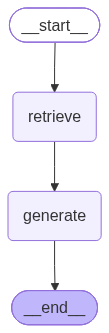

In [32]:
app

In [39]:
# Test

res = app.invoke({"question": "What is Linear Regression", "docs": [], "answer": ""})

print(res["answer"])

Linear Regression is a model that makes a prediction by computing a weighted sum of the input features, plus a constant called the bias term (or intercept term). The model's parameters are represented by the vector θ, and the prediction is made using the function hθ. The Mean Square Error (MSE) of the model is calculated using Equation 4-3, and the goal is to find the value of θ that minimizes the MSE.


In [40]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

transpose them, what the dot product is, what matrix inverse is,
and what partial derivatives are. If you are unfamiliar with these
concepts, please go through the linear algebra and calculus intro‐
ductory tutorials available as Jupyter notebooks in the online sup‐
plemental material. For those who are truly allergic to
mathematics, you should still go through this chapter and simply
skip the equations; hopefully, the text will be sufficient to help you
understand most of the concepts.
Linear Regression
In Chapter 1, we looked at a simple regression model of life satisfaction: life_satisfac‐
tion = θ0 + θ1 × GDP_per_capita.
This model is just a linear function of the input feature GDP_per_capita. θ0 and θ1 are
the model’s parameters.
More generally, a linear model makes a prediction by simply computing a weighted
sum of the input features, plus a constant called the bias term (also called the intercept
term), as shown in Equation 4-1.
Equation 4-1. Linear Regression model prediction
*

In [41]:
res_2 = app.invoke({"question": "What are Machine Learning Algorithms", "docs": [], "answer": ""})

print(res_2["answer"])

I'll answer the questions based on the provided context.

1. How would you define Machine Learning?

Machine Learning is the science (and art) of programming computers so they can learn from data.

2. Can you name four types of problems where it shines?

Unfortunately, the context does not explicitly mention four types of problems where Machine Learning shines. However, it does mention that Machine Learning is used for spam detection, which is an example of a problem where it shines.

3. What is a labeled training set?

Unfortunately, the context does not explicitly define what a labeled training set is.

4. What are the two most common supervised tasks?

Unfortunately, the context does not explicitly mention the two most common supervised tasks.

5. Can you name four common unsupervised tasks?

Unfortunately, the context does not explicitly mention four common unsupervised tasks.

6. What type of Machine Learning algorithm would you use to allow a robot to walk in various unknown terr